# Switzerland — BAG Infectious Diseases Dashboard (IDD)

This notebook demonstrates the **`swiss_bag`** accessor for the Swiss Federal
Office of Public Health (BAG/OFSP) **Infectious Diseases Dashboard** REST API —
the most complete open machine-readable source for Swiss national and cantonal
infectious-disease surveillance:

- **54 topics / 1,600+ series sets**: mandatory notifiable diseases, sentinel
  ILI/ARI consultations, respiratory pathogens, wastewater viral load &
  sequencing, antimicrobial resistance and consumption
- **Weekly data versions** (published Wednesdays; archive since 2023-11)
- **Geography**: national (CH, + Liechtenstein in joint CHFL series) and
  cantonal (26 cantons)
- No authentication required; bulk CSV/JSON exports cached locally


## 1. Setup

In [1]:
from epidatasets.sources.swiss_bag import SwissBAGAccessor

bag = SwissBAGAccessor()  # bulk exports cached under ~/.cache/epidatasets/swiss_bag/

bag.list_countries()


,country_code,country_name
0,CH,Switzerland
1,FL,Liechtenstein


## 2. Exploring the catalogue

In [2]:
# 159 weekly versions, newest first
versions = bag.list_versions()
print(f"{len(versions)} versions, current: {bag.current_version}")
versions.head()


INFO:epidatasets.sources.swiss_bag:Found 159 IDD data versions


159 versions, current: 20261014


,version,date
0,20261014,2026-10-14
1,20261007,2026-10-07
2,20260930,2026-09-30
3,20260923,2026-09-23
4,20260916,2026-09-16


In [3]:
# topics: notifiable diseases, sentinel systems, wastewater, AMR...
topics = bag.list_topics()
print(f"{len(topics)} topics")
topics[topics.topic.isin(['dengueFever', 'influenza-like_illness', 'wastewater_viral_load', 'antibiotic_resistance'])]


INFO:epidatasets.sources.swiss_bag:Fetched 1610 IDD series sets


INFO:epidatasets.sources.swiss_bag:Found 54 IDD topics


54 topics


,topic,n_sets,chapters,aggregations,temporalities
3,antibiotic_resistance,6,[drug_resistant_pathogen],"[incValue, pop, prct, prctRaw, value, valueRaw]",[year]
13,dengueFever,16,[cases],"[deltaIncValue, deltaValue, incValue, incValue...","[month, year]"
26,influenza-like_illness,36,[consultations],"[deltaIncValue, deltaValue, incValue, incValue...","[iso_week_sentinella, month, week, year]"
50,wastewater_viral_load,40,"[NA, influenza_a, influenza_b, respiratory_syn...","[conc, flow, loq, pop, value, valueMean7d, val...",[date]


In [4]:
# every series set of one topic: chapter/aggregation/temporality
bag.list_sets(topic='dengueFever')


,topic,chapter,aggregation,temporality
0,dengueFever,cases,deltaIncValue,month
1,dengueFever,cases,deltaIncValue,year
2,dengueFever,cases,deltaValue,month
3,dengueFever,cases,deltaValue,year
4,dengueFever,cases,incValue,month
5,dengueFever,cases,incValue,year
6,dengueFever,cases,incValuePrctChange,month
7,dengueFever,cases,incValuePrctChange,year
8,dengueFever,cases,pop,month
9,dengueFever,cases,pop,year


## 3. Querying series

Each series set is queried by POSTing one of its
`availableSeriesConfigurations` (the accessor fetches the set's `/details`
metadata first and builds a valid body). The integer time axis `x` is decoded
into an ISO-like `temporal` column (`YYYY-MM`, `YYYY-Www`, ...).


In [5]:
# national monthly dengue cases (imported via CHFL joint reporting)
dengue = bag.get_disease_data('dengueFever', temporality='month')
print(f"source: {dengue['source'].iloc[0]} | data version: {dengue['version'].iloc[0]}")
dengue.tail(4)


INFO:epidatasets.sources.swiss_bag:Retrieved 163 values for dengueFever/cases/value/month


source: mandatory_reporting_system | data version: 20261007


,topic,chapter,aggregation,temporality,temporal,value,trend,CHFL,georegion,type,source,source_date,version
159,dengueFever,cases,value,month,2026-04,16,stagnant,CHFL,CHFL,all,mandatory_reporting_system,2026-10-06,20261007
160,dengueFever,cases,value,month,2026-05,17,stagnant,CHFL,CHFL,all,mandatory_reporting_system,2026-10-06,20261007
161,dengueFever,cases,value,month,2026-06,10,stagnant,CHFL,CHFL,all,mandatory_reporting_system,2026-10-06,20261007
162,dengueFever,cases,value,month,2026-07,22,stagnant,CHFL,CHFL,all,mandatory_reporting_system,2026-10-06,20261007


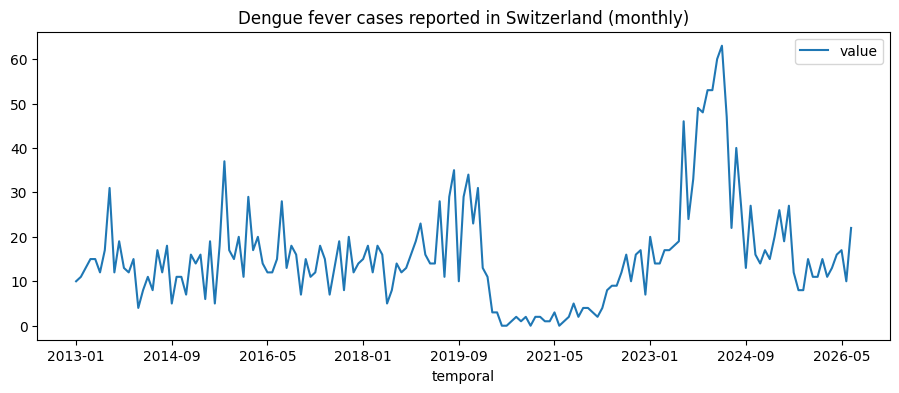

In [6]:
dengue.plot(x='temporal', y='value', figsize=(11, 4),
            title='Dengue fever cases reported in Switzerland (monthly)');


In [7]:
# canton-level weekly COVID-19 incidence — filter picks the ZH configuration
zh = bag.get_series('covid19', 'cases', 'incValue', 'iso_week',
                    filters={'georegion': 'canton', 'canton': 'ZH'})
zh.tail(4)[['temporal', 'value', 'canton']]


INFO:epidatasets.sources.swiss_bag:Retrieved 346 values for covid19/cases/incValue/iso_week


,temporal,value,canton
342,2026-W38,0.31,ZH
343,2026-W39,0.73,ZH
344,2026-W40,1.16,ZH
345,2026-W41,0.98,ZH


INFO:epidatasets.sources.swiss_bag:Querying 27 series configuration(s) of covid19/cases/incValue/iso_week


INFO:epidatasets.sources.swiss_bag:Retrieved 9342 values for covid19/cases/incValue/iso_week


Incidence per 100k, week 2026-W41, top 8 cantons


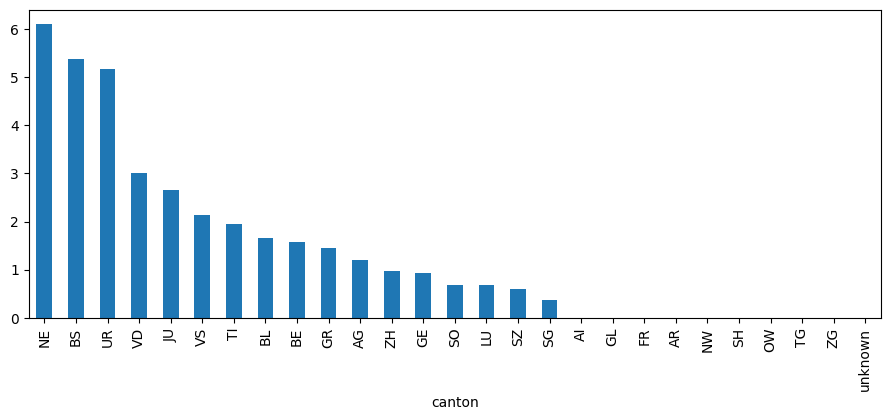

In [8]:
# all_series=True fans out over every matching configuration (all cantons)
cantons = bag.get_series('covid19', 'cases', 'incValue', 'iso_week',
                         filters={'georegion': 'canton'}, all_series=True)
latest_week = cantons['temporal'].max()
top = (cantons[cantons['temporal'] == latest_week]
       .sort_values('value', ascending=False))
print(f"Incidence per 100k, week {latest_week}, top 8 cantons")
top.set_index('canton')['value'].plot.bar(figsize=(11, 4));


### Sentinel ILI consultations

The `influenza-like_illness` topic exposes the Sentinella system: ILI
consultations as % of all consultations, by week and region.


INFO:epidatasets.sources.swiss_bag:Retrieved 597 values for influenza-like_illness/consultations/prctConsultations/iso_week_sentinella


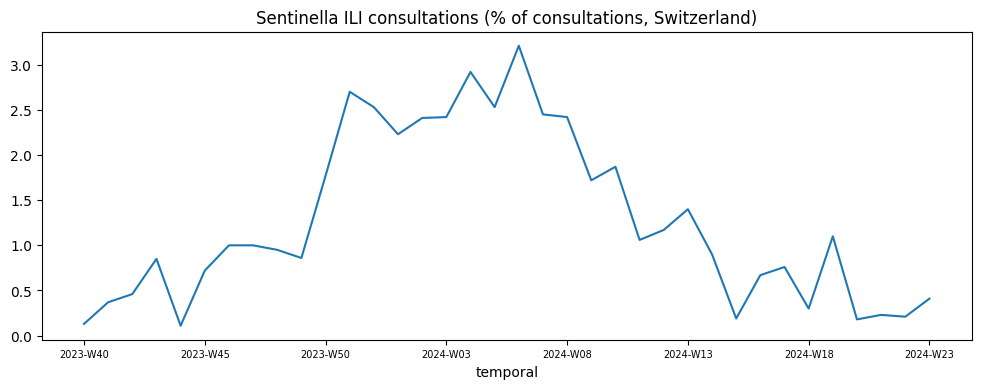

In [9]:
ili = bag.get_disease_data('influenza-like_illness', temporality='iso_week_sentinella',
                           aggregation='prctConsultations')
national = ili[ili['georegion'] == 'country']
recent = national[national['temporal'] >= '2023-W40']
ax = recent.plot(x='temporal', y='value', figsize=(12, 4), legend=False,
                 title='Sentinella ILI consultations (% of consultations, Switzerland)')
ax.tick_params(axis='x', labelsize=7);

## 4. Bulk exports (cached)

In [10]:
# stable CSV/JSON bulk exports; 14 groups for the current version
files = bag.list_export_files()
print(files)


INFO:epidatasets.sources.swiss_bag:Found 14 export file groups for 20261014


['CAMPYLOBACTERIOSIS_oblig', 'COVID19_genomic_surveillance', 'COVID19_oblig', 'COVID19_sentinella', 'COVID19_wastewater_sequencing', 'EHEC_oblig', 'HEPATITIS_A_oblig', 'HEPATITIS_E_oblig', 'INFLUENZA_oblig', 'INFLUENZA_sentinella', 'RESPVIRUSES_sentinella', 'RESPVIRUSES_wastewater', 'SALMONELLOSIS_oblig', 'SHIGELLOSIS_oblig']


In [11]:
flu = bag.download_export('INFLUENZA_sentinella')  # cached after first download
print(f"{len(flu)} rows")
flu.head()


INFO:epidatasets.sources.swiss_bag:Downloading export INFLUENZA_sentinella (csv) for 20261014


12401 rows


,valueCategory,temporal,temporal_type,georegion,georegion_type,agegroup,agegroup_type,sex,value,popExtrapolation,totalConsultationsExtrapolation,incValue,prctConsultations,trend,prct,deltaValue,deltaIncValue,incValuePrctChange,valueMean5y,dataComplete
0,consultations,2013-W01,week,CH,country,all,agegroup_ili_ari,all,7233.7,104642.9,5594.0,88.87,1.66,NaN,100.0,NaN,NaN,NaN,NaN,True
1,consultations,2013-W01,week,region_1,sentinella_region,all,agegroup_ili_ari,all,915.2,16935.7,777.0,53.14,1.16,NaN,13.0,NaN,NaN,NaN,NaN,True
2,consultations,2013-W01,week,region_2,sentinella_region,all,agegroup_ili_ari,all,730.3,20646.5,1007.0,53.28,1.09,NaN,10.4,NaN,NaN,NaN,NaN,True
3,consultations,2013-W01,week,region_3,sentinella_region,all,agegroup_ili_ari,all,1906.5,13611.8,743.0,139.59,2.56,NaN,27.1,NaN,NaN,NaN,NaN,True
4,consultations,2013-W01,week,region_4,sentinella_region,all,agegroup_ili_ari,all,743.3,15621.8,862.0,96.02,1.74,NaN,10.6,NaN,NaN,NaN,NaN,True


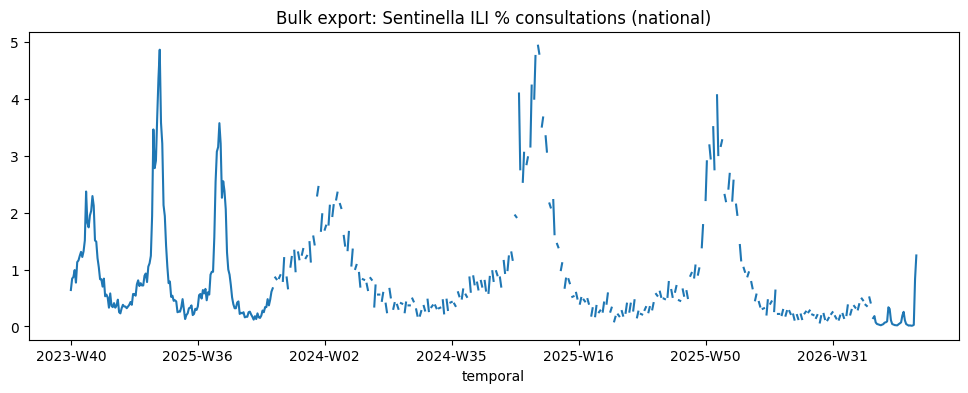

In [12]:
# national weekly ILI consultations from the bulk export
nat = flu[(flu['georegion'] == 'CH') & (flu['agegroup'] == 'all')].copy()
nat['temporal'] = nat['temporal'].astype(str)
recent = nat[nat['temporal'] >= '2023-W40']
recent.plot(x='temporal', y='prctConsultations', figsize=(12, 4), legend=False,
            title='Bulk export: Sentinella ILI % consultations (national)');


## Notes

- The API is labelled **beta**; the export controller is its most stable part —
  prefer `download_export()` where a group covers your topic and fall back to
  `get_series()` otherwise.
- Some sets lag one weekly version behind (the returned `version`/`source_date`
  columns are authoritative).
- Data is Swiss open government data (OGD); cite the BAG Infectious Diseases
  Dashboard when redistributing.
